In [17]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt # for making figures
%matplotlib inline

In [18]:
#read in all the words
words = open("../data/shakespeare_100k.txt").read().splitlines()
words[:8]

['THE', 'SONNETS', 'ALL', 'IS', 'WELL', 'THAT', 'ENDS', 'WELL']

In [19]:
# build the vocabulary of characters and mappings to/from integers
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
vocab_size = len(itos)
print(itos)
print(vocab_size)

{1: 'A', 2: 'B', 3: 'C', 4: 'D', 5: 'E', 6: 'F', 7: 'G', 8: 'H', 9: 'I', 10: 'J', 11: 'K', 12: 'L', 13: 'M', 14: 'N', 15: 'O', 16: 'P', 17: 'Q', 18: 'R', 19: 'S', 20: 'T', 21: 'U', 22: 'V', 23: 'W', 24: 'X', 25: 'Y', 26: 'a', 27: 'b', 28: 'c', 29: 'd', 30: 'e', 31: 'f', 32: 'g', 33: 'h', 34: 'i', 35: 'j', 36: 'k', 37: 'l', 38: 'm', 39: 'n', 40: 'o', 41: 'p', 42: 'q', 43: 'r', 44: 's', 45: 't', 46: 'u', 47: 'v', 48: 'w', 49: 'x', 50: 'y', 51: 'z', 0: '.'}
52


In [20]:
# build the dataset
block_size = 3 # context length: how many characters do we take to predict the next one?

def build_dataset(words):  
  X, Y = [], []
  
  for w in words:
    context = [0] * block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      context = context[1:] + [ix] # crop and append

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  print(X.shape, Y.shape)
  return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr,  Ytr  = build_dataset(words[:n1])     # 80%
Xdev, Ydev = build_dataset(words[n1:n2])   # 10%
Xte,  Yte  = build_dataset(words[n2:])     # 10%

torch.Size([407170, 3]) torch.Size([407170])
torch.Size([50885, 3]) torch.Size([50885])
torch.Size([50519, 3]) torch.Size([50519])


# Initializations

Random initilization can give very high loss in the begining as we have observed previously therefore we wast our initialization to still be random but uniformly distributed over all the chars

we can calculate the expected loss for any setup using the formula
1/(n(chars)) X log
for our case : -torch.tensor(1/51.0).log() this should be our initial loss when initializations are properly distributed

So during initialization we can just make our logits closer to zero (by multiplying with 0 or 0.1 or something, that normalizes everything to near zero) so instead of starting at random high +ve -ve numbers we start at near zero

CAUTION: we prefer not to set weights to zero so we may make it closer to 0 but not zero 

also to avoid dead neurons we set initializations to near zero 

there are techniques which tells how you can better initialize for your specific neuron activation
but very specific initializations are not very important today because of modern innovations like batch normalization etc

In [21]:
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP

C  = torch.randn((vocab_size, n_embd))
W1 = torch.randn((n_embd * block_size, n_hidden)) * (5/3)/((n_embd * block_size)**0.5) * 0.2
b1 = torch.randn(n_hidden) * 0.01
W2 = torch.randn((n_hidden, vocab_size)) * 0.01
b2 = torch.randn(vocab_size) * 0

parameters = [C, W1,b1, W2, b2]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.requires_grad = True

17172


In [22]:
# same optimization as last time
max_steps = 200
batch_size = 22
lossi = []

for i in range(max_steps):
    # minibatch construct 
    ix = torch.randint(0, Xtr.shape[0], (batch_size,))
    Xb, Yb = Xtr[ix], Ytr[ix] # batch X, Y

    # forward pass 
    emb = C[Xb] # embed the characters into vectors
    embcat = emb.view(emb.shape[0], -1) # concatenate the vectors
    hpreact = embcat @ W1 + b1 # hidden layer pre-activation
    h = torch.tanh(hpreact) # hidden layer
    logits = h @ W2 + b2 # output layer
    loss = F.cross_entropy(logits, Yb) # loss funtion

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update 
    lr = 0.1 if i< 100 else 0.01 # step learning rate decay
    for p in parameters:
        p.data += -lr * p.grad

    # track stats 
    if i%100==0:
        print(f'{i:7d}/{max_steps:7d}: {loss.item():4f}')
    lossi.append(loss.log10().item())

    


      0/    200: 3.930388


    100/    200: 3.306257


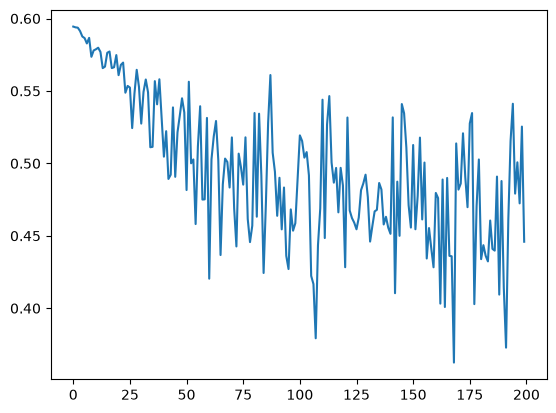

In [ ]:
plt.plot(lossi) # less hockey like structure because initializations are better

# Batch Normalization